# DATA-266 — Homework 3
Sadaf Fatima Syeda | SID4 = 2733

## Step 0: Personal Parameters

In [2]:
import random
import numpy as np
import torch

SID4 = 2733
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

SID4=2733, SEED=2733, SLICE=733, HP_ID=3, CLS_A=3, CLS_B=7


Task 1: Prompt Engineering Techniques

In [3]:
!pip install -q langchain-groq langchain-core

from getpass import getpass
import os

os.environ["GROQ_API_KEY"] = getpass("Paste your API key: ")

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.5 MB/s eta 0:00:00
Paste your API key: ··········


Zero-Shot No examples, no hints just the bare question sent directly to the model.

```

```



In [4]:
from langchain_core.prompts import ChatPromptTemplate

zero_shot_prompt = ChatPromptTemplate.from_template("{question}")
zero_shot_chain = zero_shot_prompt | llm

q1 = "If a train travels 60 miles in 45 minutes, what is its speed in miles per hour?"
resp1 = zero_shot_chain.invoke({"question": q1})
print("ZERO-SHOT Example 1:\n", resp1.content)

q2 = "All bloops are razzles. All razzles are lazzles. Are all bloops definitely lazzles? Answer Yes or No and explain why."
resp2 = zero_shot_chain.invoke({"question": q2})
print("\nZERO-SHOT Example 2:\n", resp2.content)

ZERO-SHOT Example 1:
 The speed is found by dividing distance by time.

- Distance = 60 miles  
- Time = 45 minutes = \(45/60 = 0.75\) hours  

\[
\text{Speed} = \frac{60\ \text{miles}}{0.75\ \text{hours}} = 80\ \text{miles per hour}
\]

**Answer: 80 mph**

ZERO-SHOT Example 2:
 **Yes.**

Because the statements form a transitive chain:

1. Every *bloop* is a *razzle*.  
2. Every *razzle* is a *lazzle*.

If each *bloop* belongs to the set of *razzles*, and every *razzle* belongs to the set of *lazzles*, then each *bloop* must also belong to the set of *lazzles*. This follows from the transitive property of the universal quantifier:  
\[
\forall x\, (x \text{ is a bloop} \rightarrow x \text{ is a razzle}) \land
\forall x\, (x \text{ is a razzle} \rightarrow x \text{ is a lazzle})
\implies
\forall x\, (x \text{ is a bloop} \rightarrow x \text{ is a lazzle}).
\]


Few-Shot

Two worked examples are shown before the real question, so the model can infer the expected pattern/format from them.

In [5]:
from langchain_core.prompts import FewShotPromptTemplate, PromptTemplate

example_prompt = PromptTemplate.from_template("Q: {question}\nA: {answer}")

math_examples = [
    {"question": "A car travels 120 miles in 2 hours. What is its speed in mph?",
     "answer": "120 / 2 = 60 mph"},
    {"question": "A pool holds 300 gallons and fills at 25 gallons per minute. How long to fill it?",
     "answer": "300 / 25 = 12 minutes"},
]
few_shot_math_prompt = FewShotPromptTemplate(
    examples=math_examples,
    example_prompt=example_prompt,
    suffix="Q: {question}\nA:",
    input_variables=["question"],
)
resp1_fs = llm.invoke(few_shot_math_prompt.format(question=q1))
print("FEW-SHOT Example 1:\n", resp1_fs.content)

logic_examples = [
    {"question": "All cats are mammals. All mammals are animals. Are all cats animals?",
     "answer": "Yes — cats are mammals, and mammals are animals, so cats are animals."},
    {"question": "All squares are rectangles. All rectangles have four sides. Do all squares have four sides?",
     "answer": "Yes — squares are rectangles, and rectangles have four sides, so squares have four sides."},
]
few_shot_logic_prompt = FewShotPromptTemplate(
    examples=logic_examples,
    example_prompt=example_prompt,
    suffix="Q: {question}\nA:",
    input_variables=["question"],
)
resp2_fs = llm.invoke(few_shot_logic_prompt.format(question=q2))
print("\nFEW-SHOT Example 2:\n", resp2_fs.content)

FEW-SHOT Example 1:
 The train’s speed is

\[
\text{speed} = \frac{\text{distance}}{\text{time}} = \frac{60\ \text{miles}}{45\ \text{minutes}}
\]

Convert 45 minutes to hours:

\[
45\ \text{min} = \frac{45}{60}\ \text{hr} = 0.75\ \text{hr}
\]

Now divide:

\[
\frac{60}{0.75} = 80
\]

**Answer: 80 mph**

FEW-SHOT Example 2:
 A: Yes — because every bloop is a razzzle, and every razzzle is a lazzle, so by transitivity every bloop must be a lazzle.


Chain-of-Thought (CoT)

Worked examples now show explicit step-by-step reasoning

In [6]:
cot_prompt_template = PromptTemplate.from_template("Q: {question}\nA: {answer}")

cot_math_examples = [
    {"question": "A car travels 120 miles in 2 hours. What is its speed in mph?",
     "answer": "Step 1: Speed = distance / time. Step 2: 120 miles / 2 hours = 60 mph. Final answer: 60 mph."},
    {"question": "A pool holds 300 gallons and fills at 25 gallons per minute. How long to fill it?",
     "answer": "Step 1: Time = total volume / rate. Step 2: 300 gallons / 25 gallons per minute = 12 minutes. Final answer: 12 minutes."},
]
cot_math_prompt = FewShotPromptTemplate(
    examples=cot_math_examples,
    example_prompt=cot_prompt_template,
    suffix="Q: {question}\nA: Let's think step by step.",
    input_variables=["question"],
)
resp1_cot = llm.invoke(cot_math_prompt.format(question=q1))
print("CoT Example 1:\n", resp1_cot.content)

cot_logic_examples = [
    {"question": "All cats are mammals. All mammals are animals. Are all cats animals?",
     "answer": "Step 1: Every cat belongs to the mammal group. Step 2: Every mammal belongs to the animal group. Step 3: Since cats are inside mammals, and mammals are inside animals, cats are inside animals too. Final answer: Yes."},
    {"question": "All squares are rectangles. All rectangles have four sides. Do all squares have four sides?",
     "answer": "Step 1: Every square belongs to the rectangle group. Step 2: Every rectangle has four sides. Step 3: Since squares are inside rectangles, squares also have four sides. Final answer: Yes."},
]
cot_logic_prompt = FewShotPromptTemplate(
    examples=cot_logic_examples,
    example_prompt=cot_prompt_template,
    suffix="Q: {question}\nA: Let's think step by step.",
    input_variables=["question"],
)
resp2_cot = llm.invoke(cot_logic_prompt.format(question=q2))
print("\nCoT Example 2:\n", resp2_cot.content)

CoT Example 1:
 **Step 1:** Convert the time from minutes to hours.  
\(45\ \text{minutes} = \dfrac{45}{60}\ \text{hours} = 0.75\ \text{hours}\).

**Step 2:** Use the speed formula  
\[
\text{Speed} = \frac{\text{Distance}}{\text{Time}}
\]

Plug in the values:  
\[
\text{Speed} = \frac{60\ \text{miles}}{0.75\ \text{hours}} = 80\ \text{mph}
\]

**Final answer:** The train’s speed is **80 miles per hour**.

CoT Example 2:
 **Answer: Yes.**

**Why?**  
1. **Premise 1:** Every *bloop* is a *razzle*.  
2. **Premise 2:** Every *razzle* is a *lazzle*.  
3. **Transitive property of “is a”:** If every member of group A belongs to group B, and every member of group B belongs to group C, then every member of group A must belong to group C.  
4. Applying that property, every *bloop* (group A) belongs to group C, the *lazzles*.  

Thus, all bloops are definitely lazzles.


Zero-Shot CoT

No worked examples this time — just the bare question plus the trigger phrase "Let's think step by step," to see how much of CoT's benefit comes from the phrase alone.

In [7]:
zero_shot_cot_prompt = ChatPromptTemplate.from_template("{question}\n\nLet's think step by step.")
zero_shot_cot_chain = zero_shot_cot_prompt | llm

resp1_zscot = zero_shot_cot_chain.invoke({"question": q1})
print("ZERO-SHOT COT Example 1:\n", resp1_zscot.content)

resp2_zscot = zero_shot_cot_chain.invoke({"question": q2})
print("\nZERO-SHOT COT Example 2:\n", resp2_zscot.content)

ZERO-SHOT COT Example 1:
 **Step 1: Convert the time to hours**  
- 45 minutes ÷ 60 minutes per hour = **0.75 hours**.

**Step 2: Use the speed formula**  
- Speed \(v = \dfrac{\text{distance}}{\text{time}}\).

**Step 3: Plug in the numbers**  
- \(v = \dfrac{60\ \text{miles}}{0.75\ \text{hours}}\).

**Step 4: Compute**  
- \(60 ÷ 0.75 = 80\).

---

**Answer:** The train’s speed is **80 miles per hour**.

ZERO-SHOT COT Example 2:
 **Answer: Yes**

**Step‑by‑step reasoning**

1. **Premise 1:** *All bloops are razzles.*  
   - This means every member of the set “bloops” is also a member of the set “razzles.”  
   - Symbolically: ∀x (B(x) → R(x)).

2. **Premise 2:** *All razzles are lazzles.*  
   - Every member of the set “razzles” is also a member of the set “lazzles.”  
   - Symbolically: ∀x (R(x) → L(x)).

3. **Transitive inference:**  
   - If an element x is a bloop, then by Premise 1 it is a razzle.  
   - If x is a razzle, then by Premise 2 it is a lazzle.  
   - Therefore, if x i

Meta-Prompting

Instead of a fixed reasoning format, the model is asked to first decide what type of problem this is and what strategy fits, then solve it using that self-chosen strategy.

In [8]:
meta_prompt = ChatPromptTemplate.from_template(
    "You are solving the following problem:\n{question}\n\n"
    "First, briefly decide what type of problem this is and what strategy or method is best suited to solve it. "
    "Then apply that strategy to solve the problem, showing your work, and give a final answer."
)
meta_chain = meta_prompt | llm

resp1_meta = meta_chain.invoke({"question": q1})
print("META-PROMPTING Example 1:\n", resp1_meta.content)

resp2_meta = meta_chain.invoke({"question": q2})
print("\nMETA-PROMPTING Example 2:\n", resp2_meta.content)

META-PROMPTING Example 1:
 **Type of problem**  
This is a *unit‑conversion* problem: we need to find the speed (distance per unit time) given a distance and a time that are not in the same units.

**Strategy**  
1. Convert the time from minutes to hours, because speed is requested in miles per hour.  
2. Use the speed formula  
   \[
   \text{speed} = \frac{\text{distance}}{\text{time}}
   \]
   with the distance in miles and the time in hours.

**Solution**  

1. Convert 45 minutes to hours:  
   \[
   45\ \text{min} = \frac{45}{60}\ \text{h} = 0.75\ \text{h}
   \]

2. Compute the speed:  
   \[
   \text{speed} = \frac{60\ \text{miles}}{0.75\ \text{h}}
   \]

   Divide 60 by 0.75:  
   \[
   60 \div 0.75 = 80
   \]

**Answer**  
The train’s speed is **80 miles per hour (mph)**.

META-PROMPTING Example 2:
 **Type of problem**  
This is a *logical reasoning* problem involving categorical statements (a syllogism).  
We need to determine whether the conclusion follows necessarily from th

Tree of Thoughts

Two model calls: first generate 3 independent solution attempts, then a second call compares them and picks the best, giving a final answer.

In [9]:
tot_generate_prompt = ChatPromptTemplate.from_template(
    "Problem: {question}\n\n"
    "Generate 3 different ways to approach and solve this problem. "
    "Label them Approach 1, Approach 2, Approach 3, each with brief reasoning and a final answer."
)
tot_generate_chain = tot_generate_prompt | llm

tot_evaluate_prompt = ChatPromptTemplate.from_template(
    "Here are 3 different approaches to solving this problem:\n\n{branches}\n\n"
    "Evaluate each approach for correctness, then state which one is best and give the final answer."
)
tot_evaluate_chain = tot_evaluate_prompt | llm

branches1 = tot_generate_chain.invoke({"question": q1})
print("TREE OF THOUGHTS Example 1 - Branches:\n", branches1.content)

evaluation1 = tot_evaluate_chain.invoke({"branches": branches1.content})
print("\nTREE OF THOUGHTS Example 1 - Evaluation:\n", evaluation1.content)

branches2 = tot_generate_chain.invoke({"question": q2})
print("\nTREE OF THOUGHTS Example 2 - Branches:\n", branches2.content)

evaluation2 = tot_evaluate_chain.invoke({"branches": branches2.content})
print("\nTREE OF THOUGHTS Example 2 - Evaluation:\n", evaluation2.content)

TREE OF THOUGHTS Example 1 - Branches:
 **Problem:**  
A train covers 60 miles in 45 minutes. What is its speed in miles per hour (mph)?

---

### Approach 1 – Direct Distance ÷ Time (after converting time to hours)

**Reasoning**  
Speed = distance ÷ time.  
The time is given in minutes, so first convert 45 minutes to hours:  
\(45\ \text{min} = \dfrac{45}{60}\ \text{hr} = 0.75\ \text{hr}\).

**Calculation**  
\[
\text{Speed} = \frac{60\ \text{mi}}{0.75\ \text{hr}} = 80\ \text{mph}
\]

**Answer:** **80 mph**

---

### Approach 2 – Convert to “miles per minute” then to mph

**Reasoning**  
Compute the rate in miles per minute, then scale up to an hour (60 minutes).

**Calculation**  
\[
\frac{60\ \text{mi}}{45\ \text{min}} = \frac{60}{45}\ \text{mi/min} = \frac{4}{3}\ \text{mi/min}
\]
Now convert to mph:  
\[
\frac{4}{3}\ \text{mi/min} \times 60\ \text{min/hr} = 80\ \text{mph}
\]

**Answer:** **80 mph**

---

### Approach 3 – Use a proportional scaling factor

**Reasoning**  
If 60 mil

Task 2: Self-Attention and Causal Masking
Part 1: Unmasked Self-Attention
Step 1: Tokenization

Split the text into words, lowercase, treat periods as their own token, and assign each unique word an ID number.

In [11]:
text = ("Neural networks are powerful models for learning representations from data. "
        "They consist of layers of interconnected neurons. "
        "Attention mechanisms allow models to focus on relevant parts of the input. "
        "Transformers rely entirely on attention instead of recurrence. "
        "Autoregressive models generate text one token at a time.")

tokens = text.lower().replace(".", " .").split()
vocab = sorted(set(tokens))
word2idx = {word: i for i, word in enumerate(vocab)}
idx2word = {i: word for word, i in word2idx.items()}

token_ids = [word2idx[t] for t in tokens]

print("Number of tokens:", len(tokens))
print("Vocabulary size:", len(vocab))
print("First 10 tokens:", tokens[:10])
print("First 10 token IDs:", token_ids[:10])

Number of tokens: 51
Vocabulary size: 40
First 10 tokens: ['neural', 'networks', 'are', 'powerful', 'models', 'for', 'learning', 'representations', 'from', 'data']
First 10 token IDs: [22, 21, 3, 28, 20, 11, 18, 32, 12, 8]


Trainable Embeddings

In [12]:
import torch
import torch.nn as nn

vocab_size = len(vocab)
embed_dim = 16

embedding = nn.Embedding(vocab_size, embed_dim)

token_ids_tensor = torch.tensor(token_ids, dtype=torch.long)
embeddings = embedding(token_ids_tensor)

print("Token IDs tensor shape:", token_ids_tensor.shape)
print("Embeddings shape:", embeddings.shape)
print("Embedding for first token ('neural'):\n", embeddings[0])

Token IDs tensor shape: torch.Size([51])
Embeddings shape: torch.Size([51, 16])
Embedding for first token ('neural'):
 tensor([ 0.8578, -0.1408,  1.4982,  0.2758, -1.2422,  1.7353,  0.0390, -0.4215,
        -0.3779,  0.1852,  0.1985,  1.0310, -0.6253, -0.3404, -1.2300, -0.5186],
       grad_fn=<SelectBackward0>)


Trainable Embeddings

In [13]:
import torch
import torch.nn as nn

class TinyAttentionLM(nn.Module):
    def __init__(self, vocab_size, embed_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.W_q = nn.Linear(embed_dim, embed_dim)
        self.W_k = nn.Linear(embed_dim, embed_dim)
        self.W_v = nn.Linear(embed_dim, embed_dim)
        self.output_layer = nn.Linear(embed_dim, vocab_size)
        self.embed_dim = embed_dim

    def forward(self, token_ids, mask=None):
        x = self.embedding(token_ids)

        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        scores = Q @ K.transpose(-2, -1) / (self.embed_dim ** 0.5)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn_weights = torch.softmax(scores, dim=-1)

        attn_output = attn_weights @ V
        logits = self.output_layer(attn_output)
        return logits, attn_weights

Train the Unmasked Model

In [14]:
torch.manual_seed(SEED)

model = TinyAttentionLM(vocab_size=vocab_size, embed_dim=embed_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

input_ids = token_ids_tensor[:-1]
target_ids = token_ids_tensor[1:]

num_epochs = 200
for epoch in range(num_epochs):
    optimizer.zero_grad()
    logits, _ = model(input_ids, mask=None)
    loss = loss_fn(logits, target_ids)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {loss.item():.4f}")

Epoch 20/200, Loss: 2.0423
Epoch 40/200, Loss: 0.8666
Epoch 60/200, Loss: 0.5301
Epoch 80/200, Loss: 0.4458
Epoch 100/200, Loss: 0.3647
Epoch 120/200, Loss: 0.3519
Epoch 140/200, Loss: 0.3487
Epoch 160/200, Loss: 0.3473
Epoch 180/200, Loss: 0.3464
Epoch 200/200, Loss: 0.3458


Compute Attention Weights After Training

In [15]:
model.eval()
with torch.no_grad():
    _, attn_weights = model(token_ids_tensor, mask=None)

print("Attention weights shape:", attn_weights.shape)

Attention weights shape: torch.Size([51, 51])


Visualize Unmasked Attention Heatmap

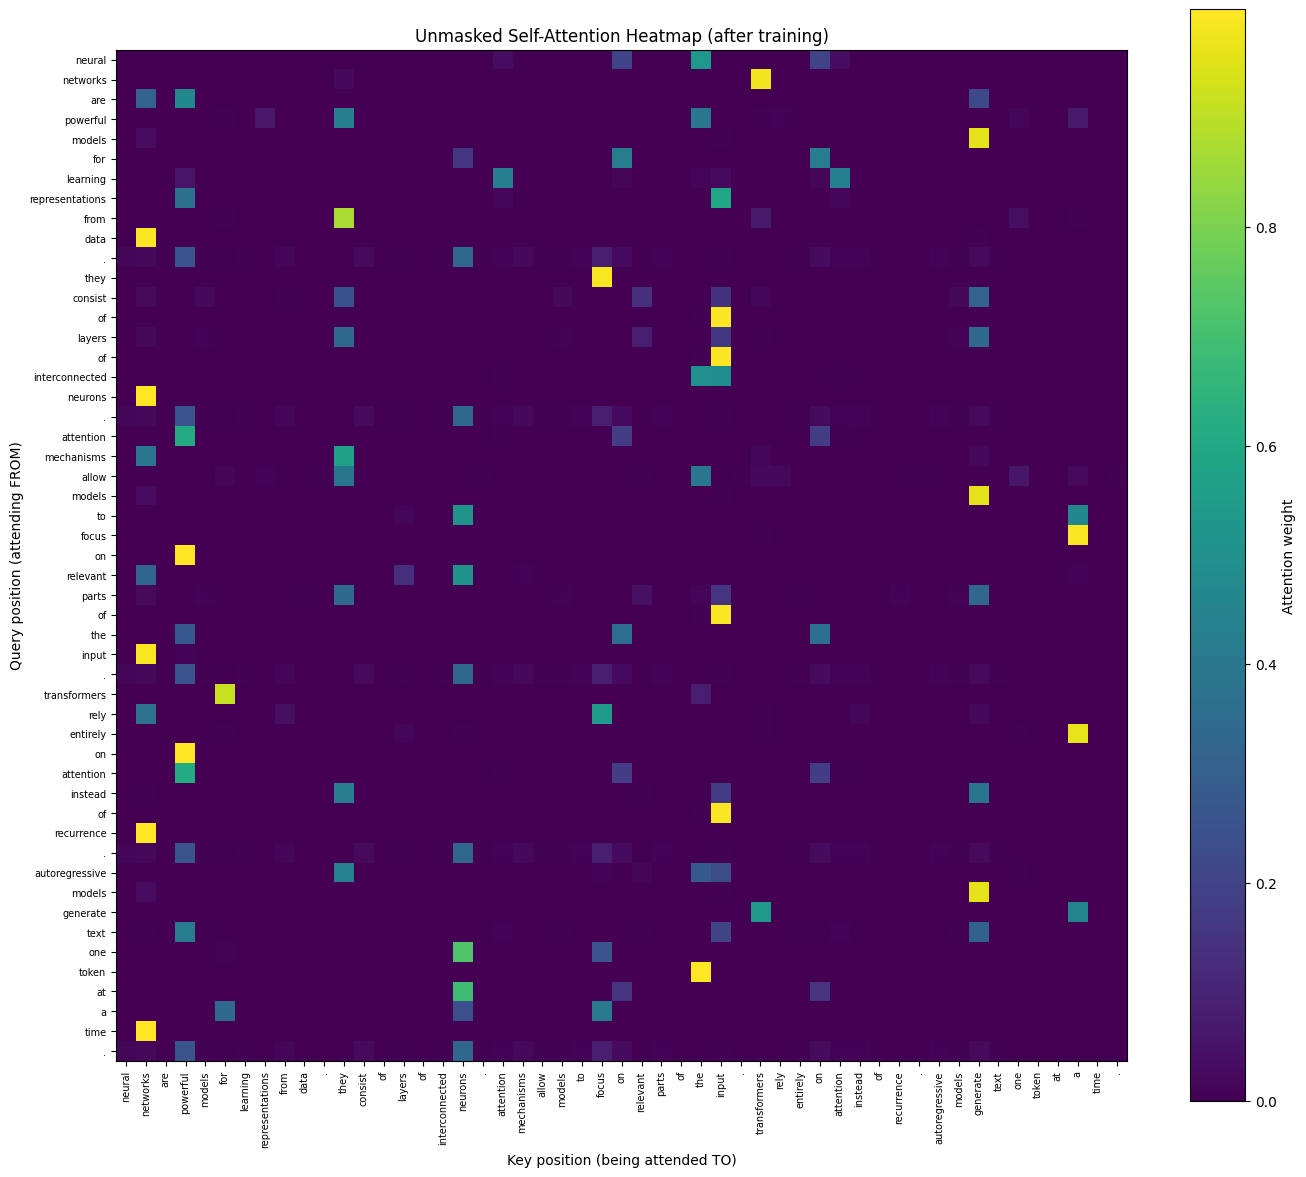

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 12))
plt.imshow(attn_weights.detach().numpy(), cmap='viridis')
plt.colorbar(label='Attention weight')
plt.xticks(range(len(tokens)), tokens, rotation=90, fontsize=7)
plt.yticks(range(len(tokens)), tokens, fontsize=7)
plt.xlabel('Key position (being attended TO)')
plt.ylabel('Query position (attending FROM)')
plt.title('Unmasked Self-Attention Heatmap (after training)')
plt.tight_layout()
plt.savefig('unmasked_attention_heatmap.png', dpi=150)
plt.show()

Causal Masking for Autoregressive Attention

In [17]:
seq_len = len(token_ids)
causal_mask = torch.tril(torch.ones(seq_len, seq_len))
print(causal_mask[:5, :5])
torch.manual_seed(SEED)

masked_model = TinyAttentionLM(vocab_size=vocab_size, embed_dim=embed_dim)
optimizer_masked = torch.optim.Adam(masked_model.parameters(), lr=0.01)

train_mask = causal_mask[:-1, :-1]

num_epochs = 200
for epoch in range(num_epochs):
    optimizer_masked.zero_grad()
    logits, _ = masked_model(input_ids, mask=train_mask)
    loss = loss_fn(logits, target_ids)
    loss.backward()
    optimizer_masked.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {loss.item():.4f}")

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])
Epoch 20/200, Loss: 2.0779
Epoch 40/200, Loss: 0.7880
Epoch 60/200, Loss: 0.4279
Epoch 80/200, Loss: 0.2919
Epoch 100/200, Loss: 0.2619
Epoch 120/200, Loss: 0.2435
Epoch 140/200, Loss: 0.2340
Epoch 160/200, Loss: 0.2379
Epoch 180/200, Loss: 0.2334
Epoch 200/200, Loss: 0.2317


Compute Masked Attention Weights

In [18]:
masked_model.eval()
with torch.no_grad():
    _, masked_attn_weights = masked_model(token_ids_tensor, mask=causal_mask)

print("Masked attention weights shape:", masked_attn_weights.shape)

Masked attention weights shape: torch.Size([51, 51])


isualize Masked Attention Heatmap

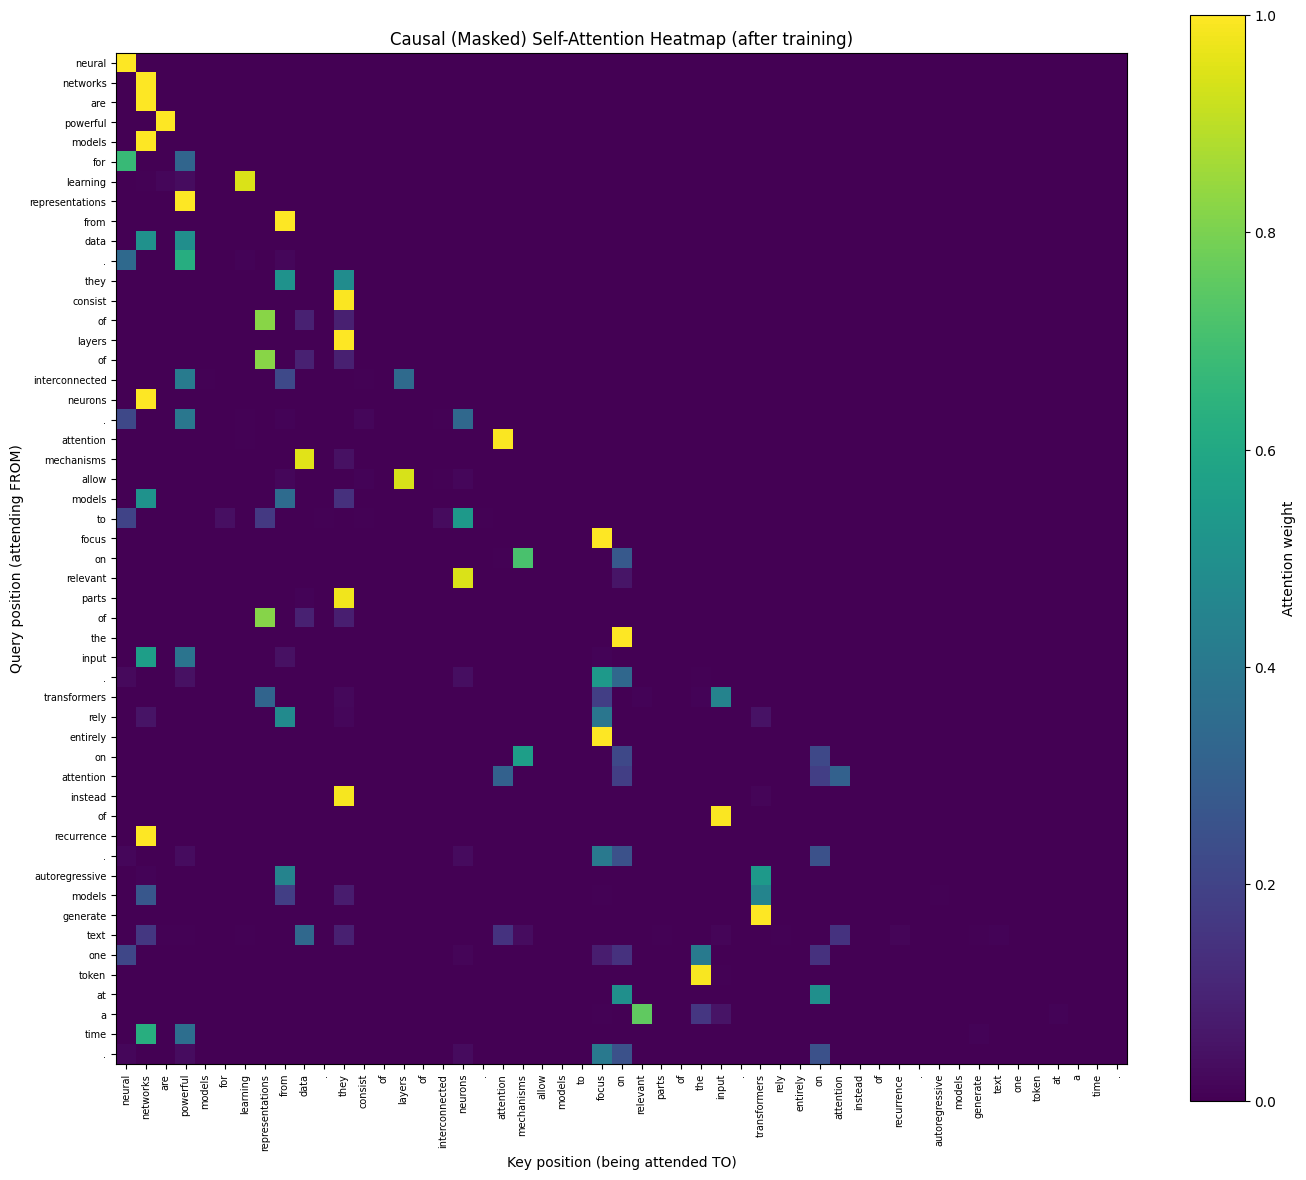

In [19]:
plt.figure(figsize=(14, 12))
plt.imshow(masked_attn_weights.detach().numpy(), cmap='viridis')
plt.colorbar(label='Attention weight')
plt.xticks(range(len(tokens)), tokens, rotation=90, fontsize=7)
plt.yticks(range(len(tokens)), tokens, fontsize=7)
plt.xlabel('Key position (being attended TO)')
plt.ylabel('Query position (attending FROM)')
plt.title('Causal (Masked) Self-Attention Heatmap (after training)')
plt.tight_layout()
plt.savefig('masked_attention_heatmap.png', dpi=150)
plt.show()